# Qwen-27B Distributed Factor-Mediator Subspace

The preceding decision-neutral recombination experiment showed a reliable answer-level interaction for weight and a weaker but consistent interaction for distance.

[实验设置与运行说明](../../../docs/experiment_notes/11_handoff_development_and_matching/751e6ccce133657d.md)


In [1]:
# Run once. Every later code cell reports both cell and inner-loop progress.
import re
import threading
import time
from IPython.core.magic import register_cell_magic
from tqdm.auto import tqdm

_SETUP_PROGRESS = tqdm(total=1, desc='Initialize progress display', unit='cell')
_ACTIVE_CELL_PROGRESS = None

def cell_stage(message):
    if _ACTIVE_CELL_PROGRESS is not None:
        _ACTIVE_CELL_PROGRESS['stage'] = str(message)
        elapsed = time.monotonic() - _ACTIVE_CELL_PROGRESS['started']
        _ACTIVE_CELL_PROGRESS['bar'].set_postfix_str(
            f"{message} | elapsed {elapsed:.0f}s", refresh=True
        )

@register_cell_magic
def cell_progress(line, cell):
    global _ACTIVE_CELL_PROGRESS
    specification = line.strip() or 'Cell progress'
    match = re.fullmatch(r'(\d+)/(\d+)\s+(.+)', specification)
    if match:
        current, total, label = int(match.group(1)), int(match.group(2)), match.group(3)
        initial = current - 1
    else:
        current, total, label, initial = 1, 1, specification, 0
    started = time.monotonic()
    bar = tqdm(
        total=total, initial=initial, desc=label, unit='cell',
        dynamic_ncols=True, leave=True,
    )
    state = {'bar': bar, 'started': started, 'stage': 'starting'}
    _ACTIVE_CELL_PROGRESS = state
    stopped = threading.Event()

    def heartbeat():
        while not stopped.wait(1.0):
            elapsed = time.monotonic() - started
            bar.set_postfix_str(
                f"{state['stage']} | elapsed {elapsed:.0f}s", refresh=True
            )

    worker = threading.Thread(target=heartbeat, daemon=True)
    worker.start()
    succeeded = False
    try:
        cell_stage('running')
        result = get_ipython().run_cell(cell)
        result.raise_error()
        succeeded = True
        return result.result
    finally:
        stopped.set()
        worker.join(timeout=2.0)
        elapsed = time.monotonic() - started
        if succeeded:
            bar.n = current
            bar.set_postfix_str(f"complete | elapsed {elapsed:.0f}s", refresh=True)
        else:
            bar.set_postfix_str(f"failed | elapsed {elapsed:.0f}s", refresh=True)
        bar.close()
        _ACTIVE_CELL_PROGRESS = None

_SETUP_PROGRESS.update(1)
_SETUP_PROGRESS.close()
print('Cell progress helper ready: 17 tracked cells.')


Initialize progress display:   0%|          | 0/1 [00:00<?, ?cell/s]

Cell progress helper ready: 17 tracked cells.


## 1. Setup


In [2]:
%%cell_progress 1/17 Mount Drive and locate VisualTorque
cell_stage('Mounting Google Drive')
from google.colab import drive
drive.mount('/content/drive')

cell_stage('Locating VisualTorque project')
from pathlib import Path
PROJECT_CANDIDATES = (
    Path('/content/drive/MyDrive/VisualTorque'),
    Path('/content/drive/MyDrive/VisualTorque/VisualTorque'),
)
PROJECT_ROOT = next(
    (
        path for path in PROJECT_CANDIDATES
        if (path / 'toolkit' / 'pyproject.toml').is_file()
    ),
    None,
)
assert PROJECT_ROOT is not None, (
    'Could not find VisualTorque/toolkit/pyproject.toml on Drive.'
)
TOOLKIT_ROOT = PROJECT_ROOT / 'toolkit'
print('Project:', PROJECT_ROOT)


Mount Drive and locate VisualTorque:   0%|          | 0/17 [00:00<?, ?cell/s]

Mounted at /content/drive
Project: /content/drive/MyDrive/VisualTorque


In [3]:
%%cell_progress 2/17 Install and verify the multimodal environment
import importlib
import subprocess
import sys

cell_stage('Removing unused TorchAudio')
subprocess.run(
    [sys.executable, '-m', 'pip', 'uninstall', '-y', 'torchaudio'],
    check=False,
)
cell_stage('Installing pinned inference and analysis dependencies')
subprocess.check_call([
    sys.executable, '-m', 'pip', 'install', '-q', '-U',
    'transformers==5.14.0', 'accelerate>=1.10', 'sentencepiece',
    'protobuf', 'huggingface_hub>=0.34', 'tqdm>=4.66',
    'pandas>=2.2', 'matplotlib>=3.8', 'scikit-learn>=1.5',
])

cell_stage('Registering the live VisualTorque source tree')
SRC_ROOT = TOOLKIT_ROOT / 'src'
PACKAGE_ROOT = SRC_ROOT / 'visual_torque_toolkit'
assert (PACKAGE_ROOT / '__init__.py').is_file(), PACKAGE_ROOT
source_text = str(SRC_ROOT)
sys.path[:] = [entry for entry in sys.path if entry != source_text]
sys.path.insert(0, source_text)
for module_name in tuple(sys.modules):
    if (
        module_name == 'visual_torque_toolkit'
        or module_name.startswith('visual_torque_toolkit.')
    ):
        del sys.modules[module_name]
importlib.invalidate_caches()

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
import visual_torque_toolkit
from IPython.display import display
from transformers import AutoModelForMultimodalLM, AutoProcessor
from visual_torque_toolkit.behavior.adapter import HuggingFaceMultimodalAdapter

required_features = (
    '_template', '_to_device', '_candidate_plan', '_append_text_prefix',
)
assert all(
    hasattr(HuggingFaceMultimodalAdapter, name)
    for name in required_features
)
toolkit_path = Path(visual_torque_toolkit.__file__).resolve()
assert PACKAGE_ROOT.resolve() in toolkit_path.parents, toolkit_path
print('torch:', torch.__version__, '| CUDA:', torch.version.cuda)
print('torchvision:', torchvision.__version__)
print('Toolkit source:', toolkit_path)


Install and verify the multimodal environment:   6%|5         | 1/17 [00:00<?, ?cell/s]

torch: 2.11.0+cu128 | CUDA: 12.8
torchvision: 0.26.0+cu128
Toolkit source: /content/drive/MyDrive/VisualTorque/toolkit/src/visual_torque_toolkit/__init__.py


In [4]:
%%cell_progress 3/17 Verify GPU and Hugging Face access
cell_stage('Checking CUDA device')
assert torch.cuda.is_available(), 'Select an A100 GPU runtime.'
print(torch.cuda.get_device_name(0))
print('CUDA memory (GB):', round(
    torch.cuda.get_device_properties(0).total_memory / 2**30, 1
))

cell_stage('Authenticating with Hugging Face')
from google.colab import userdata
from huggingface_hub import login
try:
    token = userdata.get('HF_TOKEN')
    if token:
        login(token=token, add_to_git_credential=False)
        print('Hugging Face login complete.')
    else:
        print('HF_TOKEN is not set. Public checkpoints may still work.')
except Exception as exc:
    print('Hugging Face login skipped:', exc)


Verify GPU and Hugging Face access:  12%|#1        | 2/17 [00:00<?, ?cell/s]

NVIDIA RTX PRO 6000 Blackwell Server Edition
CUDA memory (GB): 95.0
Hugging Face login skipped: Secret HF_TOKEN does not exist.


In [5]:
%%cell_progress 4/17 Lock the pilot-to-confirmation subspace protocol
cell_stage('Freezing supports, candidate sites, dimensions, controls, and gates')
import hashlib
import json
from datetime import datetime, timezone

MODEL_KEY = 'qwen27b'
MODEL_ID = 'Qwen/Qwen3.5-27B'
MODEL_SLUG = 'Qwen__Qwen3.5-27B__373612cb'
MODEL_REVISION = '373612cb4f9288fcf550b526d86d85febedd9801'
MODEL_DTYPE = 'bfloat16'
DEVICE_MAP = 'auto'
EXPECTED_LAYER_COUNT = 64
UPSTREAM_LAYER = 48
CANDIDATE_MEDIATOR_LAYERS = (49, 51, 53, 55)
CANDIDATE_DIMS = (1, 2, 4, 6)
CAPTURE_LAYERS = (UPSTREAM_LAYER,) + CANDIDATE_MEDIATOR_LAYERS
UPSTREAM_SCOPE = 'options_tokens'
MEDIATOR_SCOPE = 'final_prompt_token'
SEMANTIC_SCOPE = MEDIATOR_SCOPE

SEED = 20260923
FACTORS = ('weight', 'distance')
PILOT_PER_FACTOR = 4
CONFIRMATION_PER_FACTOR = 20
BACKGROUNDS = ('b1', 'b2')
MAPPING_VARIANTS = ('forward', 'reverse')
CONFIRMATION_CONDITIONS = (
    'additive_total', 'additive_selected_block',
    'additive_random_block', 'additive_canonical_l49_block',
    'whole_donor', 'natural_hybrid', 'self_replay', 'l49_oracle',
)
BOOTSTRAP_REPLICATES = 10000
ALPHA = 0.05
ANSWER_SESOI_LOGODDS = 0.05
MEDIATION_SESOI_LOGODDS = 0.05
ENERGY_SESOI = 0.20
SMOKE_CENTERED_LOGPROB_TOLERANCE = 0.15
NORM_RELATIVE_TOLERANCE = 1e-3
IMAGE_TOKEN_ID_OVERRIDE = None

PRIOR_ROOT = (
    PROJECT_ROOT / 'results'
    / 'qwen27b_decision_neutral_factor_semantic_mediation_v1'
)
PRIOR_MANIFEST_PATH = PRIOR_ROOT / 'decision_neutral_manifest.jsonl'
PRIOR_DECISION_PATH = PRIOR_ROOT / 'analysis' / 'factor_semantic_decision.json'
PRIOR_AUDIT_PATH = PRIOR_ROOT / 'analysis' / 'robustness_audit.json'
PRIOR_RUN_PATH = PRIOR_ROOT / 'RUN_COMPLETE.json'
AXIS_ROOT = PROJECT_ROOT / 'results' / 'qwen27b_symmetric_code_axis_v1'
SEMANTIC_TENSOR_PATH = AXIS_ROOT / 'direction_tensors.pt'

SHARED_ROOT = (
    PROJECT_ROOT / 'results'
    / 'qwen27b_distributed_factor_mediator_subspace_v1'
)
PROTOCOL_LOCK_PATH = SHARED_ROOT / 'frozen_protocol.json'
SUPPORT_LOCK_PATH = SHARED_ROOT / 'support_lock.json'
PILOT_DELTA_DIR = SHARED_ROOT / 'pilot_delta_shards'
PILOT_SCAN_DIR = SHARED_ROOT / 'pilot_scan_shards'
CONFIRMATION_DIR = SHARED_ROOT / 'confirmation_shards'
ANALYSIS_DIR = SHARED_ROOT / 'analysis'
FIGURE_DIR = ANALYSIS_DIR / 'figures'
SELECTION_PATH = ANALYSIS_DIR / 'frozen_selection.json'
BASIS_PATH = ANALYSIS_DIR / 'frozen_bases.pt'
for path in (
    SHARED_ROOT, PILOT_DELTA_DIR, PILOT_SCAN_DIR,
    CONFIRMATION_DIR, ANALYSIS_DIR, FIGURE_DIR,
):
    path.mkdir(parents=True, exist_ok=True)

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return 'sha256:' + digest.hexdigest()

def write_json_atomic(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + '.tmp')
    temporary.write_text(
        json.dumps(value, indent=2, ensure_ascii=False) + '\n',
        encoding='utf-8',
    )
    temporary.replace(path)

def read_jsonl(path):
    with Path(path).open('r', encoding='utf-8') as handle:
        return [json.loads(line) for line in handle if line.strip()]

def stable_key(value):
    return hashlib.sha256(f'{SEED}:{value}'.encode('utf-8')).hexdigest()

for required in (
    PRIOR_MANIFEST_PATH, PRIOR_DECISION_PATH, PRIOR_AUDIT_PATH,
    PRIOR_RUN_PATH, SEMANTIC_TENSOR_PATH,
):
    assert required.is_file(), f'Missing prerequisite: {required}'

prior_decision = json.loads(PRIOR_DECISION_PATH.read_text(encoding='utf-8'))
prior_audit = json.loads(PRIOR_AUDIT_PATH.read_text(encoding='utf-8'))
assert prior_decision['primary_decision'] == (
    'no_decision_neutral_factor_recombination_at_frozen_site'
)
assert int(prior_audit['physics_violations']) == 0
semantic_tensors = torch.load(
    SEMANTIC_TENSOR_PATH, map_location='cpu', weights_only=False
)
SEMANTIC_DIRECTION = semantic_tensors['semantic_direction'].float()
if SEMANTIC_DIRECTION.ndim == 1:
    SEMANTIC_DIRECTION = SEMANTIC_DIRECTION.unsqueeze(0)
SEMANTIC_STEERING_NORM = float(torch.linalg.vector_norm(SEMANTIC_DIRECTION))
assert SEMANTIC_DIRECTION.shape[0] == 1 and SEMANTIC_STEERING_NORM > 0
SEMANTIC_UNIT = SEMANTIC_DIRECTION / SEMANTIC_STEERING_NORM

protocol_identity = {
    'schema_version': 'qwen27b-distributed-factor-mediator-subspace-1.0',
    'analysis_status': (
        'pilot-selected mechanism follow-up; confirmation held out from '
        'current fit but previously seen upstream'
    ),
    'model_id': MODEL_ID,
    'revision': MODEL_REVISION,
    'upstream_site': [UPSTREAM_LAYER, UPSTREAM_SCOPE],
    'candidate_mediator_layers': list(CANDIDATE_MEDIATOR_LAYERS),
    'candidate_dimensions': list(CANDIDATE_DIMS),
    'mediator_scope': MEDIATOR_SCOPE,
    'factors': list(FACTORS),
    'pilot_per_factor': PILOT_PER_FACTOR,
    'confirmation_per_factor': CONFIRMATION_PER_FACTOR,
    'backgrounds': list(BACKGROUNDS),
    'selection': (
        'leave-one-family-out pilot specificity with dimension penalty; '
        'one frozen layer and dimension per factor'
    ),
    'confirmation_conditions': list(CONFIRMATION_CONDITIONS),
    'primary_unit': 'family mean over two target backgrounds',
    'answer_sesoi_logodds': ANSWER_SESOI_LOGODDS,
    'mediation_sesoi_logodds': MEDIATION_SESOI_LOGODDS,
    'energy_sesoi': ENERGY_SESOI,
    'bootstrap_replicates': BOOTSTRAP_REPLICATES,
    'prior_manifest_sha256': sha256_file(PRIOR_MANIFEST_PATH),
    'prior_decision_sha256': sha256_file(PRIOR_DECISION_PATH),
    'semantic_direction_sha256': sha256_file(SEMANTIC_TENSOR_PATH),
    'seed': SEED,
}
if PROTOCOL_LOCK_PATH.is_file():
    previous_lock = json.loads(
        PROTOCOL_LOCK_PATH.read_text(encoding='utf-8')
    )
    assert previous_lock.get('identity') == protocol_identity, (
        'Existing protocol differs. Use a new versioned output directory.'
    )
else:
    write_json_atomic(PROTOCOL_LOCK_PATH, {
        'identity': protocol_identity,
        'locked_at_utc': datetime.now(timezone.utc).isoformat(),
    })

print('Model:', MODEL_ID, '@', MODEL_REVISION)
print('Pilot candidates:', CANDIDATE_MEDIATOR_LAYERS, CANDIDATE_DIMS)
print('Confirmation gates:', ANSWER_SESOI_LOGODDS,
      MEDIATION_SESOI_LOGODDS, ENERGY_SESOI)
print('Output:', SHARED_ROOT)


Lock the pilot-to-confirmation subspace protocol:  18%|#7        | 3/17 [00:00<?, ?cell/s]

Model: Qwen/Qwen3.5-27B @ 373612cb4f9288fcf550b526d86d85febedd9801
Pilot candidates: (49, 51, 53, 55) (1, 2, 4, 6)
Confirmation gates: 0.05 0.05 0.2
Output: /content/drive/MyDrive/VisualTorque/results/qwen27b_distributed_factor_mediator_subspace_v1


In [6]:
%%cell_progress 5/17 Prepare Dataset v1 on local SSD
cell_stage('Checking local and Drive dataset caches')
from zipfile import ZipFile

REQUIRED_DATASET_FILES = {
    'dataset_config.json', 'scenes.jsonl', 'counterfactual_pairs.jsonl',
    'questions.jsonl', 'splits.json', 'statistics.json',
}
DATASET_DIR = Path('/content/visualtorque_dataset_v1')
DATASET_ARCHIVE = PROJECT_ROOT / 'data' / 'dataset_v1.zip'
LEGACY_DATASET_DIR = PROJECT_ROOT / 'data' / 'dataset_v1'

def dataset_complete(path):
    return path.is_dir() and all(
        (path / name).is_file() for name in REQUIRED_DATASET_FILES
    )

if not dataset_complete(DATASET_DIR):
    DATASET_DIR.mkdir(parents=True, exist_ok=True)
    if DATASET_ARCHIVE.is_file():
        cell_stage('Extracting Dataset v1 archive')
        with ZipFile(DATASET_ARCHIVE, 'r') as bundle:
            members = [m for m in bundle.infolist() if not m.is_dir()]
            root = DATASET_DIR.resolve()
            for member in tqdm(members, desc='Extracting Dataset v1', unit='file'):
                target = (DATASET_DIR / member.filename).resolve()
                if root not in target.parents:
                    raise ValueError(f'Unsafe archive path: {member.filename}')
                bundle.extract(member, DATASET_DIR)
    elif dataset_complete(LEGACY_DATASET_DIR):
        DATASET_DIR = LEGACY_DATASET_DIR
    else:
        raise FileNotFoundError(
            'Run the Dataset v1 build/cache cell in the behavior notebook first.'
        )
assert dataset_complete(DATASET_DIR)
print('Dataset:', DATASET_DIR)


Prepare Dataset v1 on local SSD:  24%|##3       | 4/17 [00:00<?, ?cell/s]

Extracting Dataset v1:   0%|          | 0/2106 [00:00<?, ?file/s]

Dataset: /content/visualtorque_dataset_v1


In [7]:
%%cell_progress 6/17 Load and lock the pilot-confirmation support
cell_stage('Loading the exact decision-neutral manifest without reselection')
from collections import Counter, defaultdict

from visual_torque_toolkit.behavior import (
    BehaviorRunConfig, PromptCondition, load_behavior_examples,
)

decision_neutral_manifest = read_jsonl(PRIOR_MANIFEST_PATH)
assert len(decision_neutral_manifest) == 48
assert Counter(row['factor'] for row in decision_neutral_manifest) == {
    'weight': 24, 'distance': 24,
}
assert Counter(row['split'] for row in decision_neutral_manifest) == {
    'pilot': 8, 'confirmation': 40,
}
for row in decision_neutral_manifest:
    assert row['factor'] in FACTORS
    expected = PILOT_PER_FACTOR if row['split'] == 'pilot' else CONFIRMATION_PER_FACTOR
    assert sum(
        other['factor'] == row['factor'] and other['split'] == row['split']
        for other in decision_neutral_manifest
    ) == expected
    for background in BACKGROUNDS:
        target = row['roles'][f'target_{background}']['outcome']
        hybrid = row['roles'][f'hybrid_{background}']['outcome']
        assert row['roles']['anchor']['outcome'] == target
        assert row['roles']['source']['outcome'] == target
        assert hybrid != target

pilot_manifest = sorted(
    [row for row in decision_neutral_manifest if row['split'] == 'pilot'],
    key=lambda row: row['family_id'],
)
confirmation_manifest = sorted(
    [row for row in decision_neutral_manifest if row['split'] == 'confirmation'],
    key=lambda row: row['family_id'],
)
support_identity = {
    'prior_manifest_sha256': sha256_file(PRIOR_MANIFEST_PATH),
    'pilot_family_ids': [row['family_id'] for row in pilot_manifest],
    'confirmation_family_ids': [row['family_id'] for row in confirmation_manifest],
}
if SUPPORT_LOCK_PATH.is_file():
    assert json.loads(SUPPORT_LOCK_PATH.read_text(encoding='utf-8')) == support_identity
else:
    write_json_atomic(SUPPORT_LOCK_PATH, support_identity)

scene_records = read_jsonl(DATASET_DIR / 'scenes.jsonl')
example_config = BehaviorRunConfig(
    dataset_dir=DATASET_DIR,
    output_dir=SHARED_ROOT / '_example_loader',
    model_id=MODEL_ID,
    conditions=(PromptCondition.IMAGE_RULE,),
    question_kinds=('outcome',),
    batch_size=1,
)
outcome_examples = tuple(load_behavior_examples(example_config))
outcome_by_scene = {
    str(example.scene_id): example
    for example in outcome_examples
    if example.variant == 'permutation_0'
}
assert len(outcome_by_scene) == len(scene_records)
print('Pilot / confirmation families:',
      len(pilot_manifest), len(confirmation_manifest))
print('Important status: confirmation is held out from this fit, not globally new.')


Load and lock the pilot-confirmation support:  29%|##9       | 5/17 [00:00<?, ?cell/s]

Pilot / confirmation families: 8 40
Important status: confirmation is held out from this fit, not globally new.


In [8]:
%%cell_progress 7/17 Load the pinned Qwen-27B decoder
cell_stage(f'Loading {MODEL_KEY} weights for recombination')
import gc
if 'adapter' in globals():
    del adapter
    gc.collect()
    torch.cuda.empty_cache()

adapter = HuggingFaceMultimodalAdapter(
    MODEL_ID, revision=MODEL_REVISION,
    dtype=MODEL_DTYPE, device_map=DEVICE_MAP,
)
display(adapter.metadata)

def resolve_module_path(root, path):
    value = root
    for component in path.split('.'):
        value = getattr(value, component)
    return value

def discover_decoder_layers(model):
    candidates = (
        'model.language_model.layers', 'model.text_model.layers',
        'language_model.model.layers', 'model.model.layers',
        'model.layers',
    )
    for path in candidates:
        try:
            layers = resolve_module_path(model, path)
        except AttributeError:
            continue
        if isinstance(layers, torch.nn.ModuleList) and len(layers) >= 8:
            return path, layers
    raise RuntimeError('Could not locate decoder layers.')

LAYER_PATH, DECODER_LAYERS = discover_decoder_layers(adapter.model)
assert len(DECODER_LAYERS) == EXPECTED_LAYER_COUNT
assert all(0 <= layer < len(DECODER_LAYERS) for layer in CAPTURE_LAYERS)
print('Layer path:', LAYER_PATH)
print('Capture layers:', CAPTURE_LAYERS)


Load the pinned Qwen-27B decoder:  35%|###5      | 6/17 [00:00<?, ?cell/s]

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/7.76k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.13k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/16.7k [00:00<?, ?B/s]

...

[transformers] The fast path is not available because one of the required library is not installed. Falling back to torch implementation. To install follow https://github.com/fla-org/flash-linear-attention#installation and https://github.com/Dao-AILab/causal-conv1d


Loading weights:   0%|          | 0/1184 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/244 [00:00<?, ?B/s]

{'adapter': 'HuggingFaceMultimodalAdapter',
 'model_id': 'Qwen/Qwen3.5-27B',
 'requested_revision': '373612cb4f9288fcf550b526d86d85febedd9801',
 'resolved_revision': '373612cb4f9288fcf550b526d86d85febedd9801',
 'dtype': 'bfloat16',
 'device_map': 'auto',
 'parameter_count': 27356728560,
 'torch_version': '2.11.0+cu128',
 'transformers_version': '5.14.0'}

Layer path: model.language_model.layers
Capture layers: (48, 49, 51, 53, 55)


## 2. Pilot-only distributed mediator discovery


In [9]:
%%cell_progress 8/17 Define counterbalanced prompts and exact token masks
cell_stage('Defining label-swapped outcome bundles')
import math
from dataclasses import replace as dataclass_replace

RULE_TEXT = (
    'Each square is one unit of weight. Distance is measured in tick '
    'intervals from the center pivot. Torque equals weight times distance. '
    'Total torque on a side is the sum over stacks on that side.'
)
QUESTION_TEXT = 'Which way will the balance scale tip?'
SEMANTIC_TEXT = {
    'left': 'left side', 'balanced': 'equal', 'right': 'right side',
}

def mapping_for(row, background_index):
    variant = MAPPING_VARIANTS[
        (int(row['counterbalance_phase']) + background_index) % 2
    ]
    semantics = (
        ('left', 'balanced', 'right')
        if variant == 'forward'
        else ('right', 'balanced', 'left')
    )
    return variant, tuple(zip(('A', 'B', 'C'), semantics))

def custom_prompt(mapping):
    options = '\n'.join(
        f'{label}. {SEMANTIC_TEXT[semantic]}'
        for label, semantic in mapping
    )
    return '\n\n'.join([
        'Answer this question using only the supplied balance-scale scene.',
        RULE_TEXT,
        'Question: ' + QUESTION_TEXT,
        'Options:\n' + options,
        'Do not explain your reasoning. Reply with exactly one option '
        'letter and nothing else. Valid replies are: A, B, C.',
    ])

def make_example(row, role_name, mapping, background, mapping_variant):
    role = row['roles'][role_name]
    scene_id = str(role['scene_id'])
    semantics = tuple(value for _, value in mapping)
    labels = tuple(label for label, _ in mapping)
    outcome = str(role['outcome'])
    base = outcome_by_scene[scene_id]
    return dataclass_replace(
        base,
        example_id=(
            f"decision_neutral:{row['family_id']}:{background}:"
            f"{mapping_variant}:{role_name}"
        ),
        question_id=(
            f"decision_neutral_{row['family_id']}_{background}_"
            f"{mapping_variant}"
        ),
        question_kind='outcome',
        variant='decision_neutral_factor_semantic',
        prompt=custom_prompt(mapping),
        labels=labels,
        option_text=tuple(SEMANTIC_TEXT[value] for value in semantics),
        option_semantics=semantics,
        gold_label=labels[semantics.index(outcome)],
        gold_semantic=outcome,
    )

def make_bundle(row, background_index):
    background = BACKGROUNDS[background_index]
    target_role = f'target_{background}'
    hybrid_role = f'hybrid_{background}'
    mapping_variant, mapping = mapping_for(row, background_index)
    role_names = ('anchor', 'source', target_role, hybrid_role)
    examples = {
        role: make_example(
            row, role, mapping, background, mapping_variant
        )
        for role in role_names
    }
    target_semantic = row['roles'][target_role]['outcome']
    hybrid_semantic = row['roles'][hybrid_role]['outcome']
    assert target_semantic == row['roles']['source']['outcome']
    assert target_semantic != hybrid_semantic
    return {
        'background': background,
        'mapping_variant': mapping_variant,
        'mapping': mapping,
        'examples': examples,
        'anchor_role': 'anchor',
        'source_role': 'source',
        'target_role': target_role,
        'hybrid_role': hybrid_role,
        'target_semantic': target_semantic,
        'hybrid_semantic': hybrid_semantic,
    }

def output_hidden_tensor(output):
    if torch.is_tensor(output):
        hidden = output
    elif isinstance(output, (tuple, list)) and output and torch.is_tensor(output[0]):
        hidden = output[0]
    elif hasattr(output, 'last_hidden_state') and torch.is_tensor(
        output.last_hidden_state
    ):
        hidden = output.last_hidden_state
    else:
        raise TypeError(f'Unsupported output: {type(output).__name__}')
    assert hidden.ndim == 3
    return hidden

def replace_output_hidden(output, modified):
    if torch.is_tensor(output):
        return modified
    if isinstance(output, tuple):
        return (modified,) + output[1:]
    if isinstance(output, list):
        return [modified] + output[1:]
    raise TypeError(type(output).__name__)

def prepare_examples(examples):
    examples = tuple(examples)
    plan = adapter._candidate_plan(examples[0])
    if plan is None:
        raise RuntimeError('A/B/C labels must be single-token candidates.')
    for example in examples[1:]:
        assert adapter._candidate_plan(example) == plan
    fixed_prefix, token_by_label = plan
    inputs = adapter._append_text_prefix(
        adapter._to_device(adapter._template(
            [example.messages() for example in examples],
            add_generation_prompt=True,
        )),
        fixed_prefix,
    )
    return {
        'examples': examples,
        'inputs': inputs,
        'token_by_label': token_by_label,
    }

def discover_masks(prepared):
    assert len(prepared['examples']) == 1
    example = prepared['examples'][0]
    ids = prepared['inputs']['input_ids'][0].detach().cpu()
    attention = prepared['inputs']['attention_mask'][0].detach().cpu().bool()
    tokenizer = getattr(adapter.processor, 'tokenizer', adapter.processor)
    tokens = tokenizer.convert_ids_to_tokens(ids.tolist())
    image_ids = set()
    if IMAGE_TOKEN_ID_OVERRIDE is not None:
        values = (
            IMAGE_TOKEN_ID_OVERRIDE
            if isinstance(IMAGE_TOKEN_ID_OVERRIDE, (list, tuple))
            else [IMAGE_TOKEN_ID_OVERRIDE]
        )
        image_ids.update(int(value) for value in values)
    for token_id, token_text in zip(ids.tolist(), tokens):
        lower = str(token_text).lower()
        if any(marker in lower for marker in ('image', 'vision', '<img', 'img>')):
            image_ids.add(int(token_id))
    image = torch.tensor(
        [int(token_id) in image_ids for token_id in ids.tolist()],
        dtype=torch.bool,
    ) & attention
    assert bool(image.any()), 'No image tokens detected.'
    final = torch.zeros_like(attention)
    final[int(torch.where(attention)[0][-1])] = True
    all_text = attention & ~image & ~final

    encoding = tokenizer(
        example.prompt, add_special_tokens=False,
        return_offsets_mapping=True,
    )
    prompt_ids = list(encoding['input_ids'])
    offsets = list(encoding['offset_mapping'])
    id_list = ids.tolist()
    starts = [
        start for start in range(len(ids) - len(prompt_ids) + 1)
        if id_list[start:start + len(prompt_ids)] == prompt_ids
    ]
    assert len(starts) == 1, len(starts)
    prompt_start = starts[0]
    sections = example.prompt.split('\n\n')
    assert len(sections) == 5
    names = (
        'intro_tokens', 'rule_tokens', 'question_tokens',
        'options_tokens', 'answer_instruction_tokens',
    )
    masks = {
        'valid_tokens': attention,
        'image_tokens': image,
        'all_text_except_final': all_text,
        'final_prompt_token': final,
    }
    spans = []
    cursor = 0
    for name, section in zip(names, sections):
        start = example.prompt.find(section, cursor)
        end = start + len(section)
        cursor = end
        spans.append((name, start, end))
        masks[name] = torch.zeros_like(attention)
    for offset_index, (token_start, token_end) in enumerate(offsets):
        overlaps = [
            (max(0, min(token_end, end) - max(token_start, start)), name)
            for name, start, end in spans
        ]
        overlap, name = max(overlaps)
        full_index = prompt_start + offset_index
        if overlap > 0 and bool(all_text[full_index]):
            masks[name][full_index] = True
    covered = torch.zeros_like(attention)
    for name in names:
        covered |= masks[name]
    masks['separator_chat_tokens'] = all_text & ~covered
    assert torch.equal(
        masks['options_tokens'] | masks['intro_tokens']
        | masks['rule_tokens'] | masks['question_tokens']
        | masks['answer_instruction_tokens']
        | masks['separator_chat_tokens'],
        all_text,
    )
    masks['tokens'] = tokens
    return masks

def assert_aligned(prepared_by_name):
    names = list(prepared_by_name)
    reference = prepared_by_name[names[0]]
    reference_masks = discover_masks(reference)
    for name in names[1:]:
        current = prepared_by_name[name]
        for key in ('input_ids', 'attention_mask'):
            assert torch.equal(reference['inputs'][key], current['inputs'][key]), (
                name, key
            )
        masks = discover_masks(current)
        for scope in (UPSTREAM_SCOPE, SEMANTIC_SCOPE):
            assert torch.equal(reference_masks[scope], masks[scope]), (
                name, scope
            )
    return reference_masks

print('Counterbalanced outcome prompts and masks ready.')


Define counterbalanced prompts and exact token masks:  41%|####1     | 7/17 [00:00<?, ?cell/s]

Counterbalanced outcome prompts and masks ready.


In [10]:
%%cell_progress 9/17 Define capture, subspace, and intervention helpers
cell_stage('Defining distributed mediator capture and equal-norm controls')
import math

def score_record(prepared, logits):
    assert len(prepared['examples']) == 1
    example = prepared['examples'][0]
    logprobs = torch.log_softmax(logits[0, -1, :].float(), dim=-1)
    scores = [
        float(logprobs[prepared['token_by_label'][label]].detach().cpu())
        for label in example.labels
    ]
    maximum = max(scores)
    weights = [math.exp(value - maximum) for value in scores]
    total = sum(weights)
    predicted_index = int(np.argmax(scores))
    return {
        'scene_id': str(example.scene_id),
        'example_id': str(example.example_id),
        'candidate_semantics': list(example.option_semantics),
        'candidate_logprobs': scores,
        'candidate_probabilities': [value / total for value in weights],
        'predicted_semantic': example.option_semantics[predicted_index],
        'gold_semantic': example.gold_semantic,
    }

def semantic_margin(record, positive, negative):
    mapping = dict(zip(
        record['candidate_semantics'], record['candidate_logprobs']
    ))
    return float(mapping[positive] - mapping[negative])

def forward_capture(prepared, upstream_payload=None, upstream_mode=None):
    masks = discover_masks(prepared)
    upstream_mask = masks[UPSTREAM_SCOPE]
    final_mask = masks[MEDIATOR_SCOPE]
    assert int(final_mask.sum()) == 1
    hidden_by_layer = {}
    handles = []

    if upstream_payload is not None:
        def upstream_edit(_module, _inputs, output):
            hidden = output_hidden_tensor(output)
            selected = upstream_mask.to(hidden.device)
            payload = upstream_payload.to(hidden.device, hidden.dtype)
            modified = hidden.clone()
            if upstream_mode == 'add':
                modified[0, selected] = hidden[0, selected] + payload[selected]
            elif upstream_mode == 'replace':
                modified[0, selected] = payload[selected]
            else:
                raise ValueError(upstream_mode)
            return replace_output_hidden(output, modified)
        handles.append(
            DECODER_LAYERS[UPSTREAM_LAYER].register_forward_hook(upstream_edit)
        )

    for layer_index in CAPTURE_LAYERS:
        def capture(_module, _inputs, output, layer_index=layer_index):
            hidden = output_hidden_tensor(output)[0]
            if layer_index == UPSTREAM_LAYER:
                value = hidden.detach().cpu().clone()
            else:
                value = hidden[final_mask.to(hidden.device)].detach().cpu().float()
            hidden_by_layer[layer_index] = value
        handles.append(
            DECODER_LAYERS[layer_index].register_forward_hook(capture)
        )
    try:
        with torch.inference_mode():
            output = adapter.model(**prepared['inputs'], use_cache=False)
    finally:
        for handle in handles:
            handle.remove()
    return score_record(prepared, output.logits), hidden_by_layer, masks

def capture_bundle(bundle):
    prepared = {
        name: prepare_examples([example])
        for name, example in bundle['examples'].items()
    }
    masks = assert_aligned(prepared)
    scores, hidden = {}, {}
    for name in prepared:
        scores[name], hidden[name], _ = forward_capture(prepared[name])
        torch.cuda.empty_cache()
    return scores, hidden, masks

def fit_basis(vectors, dimension):
    matrix = torch.stack([vector.reshape(-1).float() for vector in vectors])
    assert matrix.shape[0] >= dimension, (matrix.shape, dimension)
    assert bool(torch.isfinite(matrix).all())
    _, _, vh = torch.linalg.svd(matrix, full_matrices=False)
    basis = vh[:dimension].contiguous()
    gram = basis @ basis.T
    assert torch.allclose(
        gram, torch.eye(dimension), atol=1e-4, rtol=1e-4
    )
    return basis

def project_vector(vector, basis):
    vector = vector.reshape(1, -1).float()
    basis = basis.float()
    return (vector @ basis.T) @ basis

def random_basis_like(basis, key):
    basis = basis.float().cpu()
    generator = torch.Generator(device='cpu')
    generator.manual_seed(int(stable_key(key)[:16], 16) % (2**63 - 1))
    noise = torch.randn(
        (basis.shape[1], basis.shape[0]),
        generator=generator, dtype=torch.float32,
    )
    noise = noise - basis.T @ (basis @ noise)
    q, _ = torch.linalg.qr(noise, mode='reduced')
    random_basis = q.T.contiguous()
    assert random_basis.shape == basis.shape
    assert float(torch.linalg.vector_norm(random_basis @ basis.T)) < 1e-3
    return random_basis

def centered_error(first, second):
    first = np.asarray(first, dtype=float)
    second = np.asarray(second, dtype=float)
    return float(np.max(np.abs(
        (first - first.mean()) - (second - second.mean())
    )))

def score_intervention(
    example, clean_mediator, upstream_payload, upstream_mode,
    block_layer=None, block_mode='none', basis=None, random_basis=None,
    desired_semantic=None, condition='unknown',
):
    prepared = prepare_examples([example])
    masks = discover_masks(prepared)
    upstream_mask = masks[UPSTREAM_SCOPE]
    final_mask = masks[MEDIATOR_SCOPE]
    measurements = {
        'selected_component_norm': 0.0,
        'random_component_norm': 0.0,
        'explained_energy': 0.0,
    }

    def upstream_hook(_module, _inputs, output):
        hidden = output_hidden_tensor(output)
        selected = upstream_mask.to(hidden.device)
        payload = upstream_payload.to(hidden.device, hidden.dtype)
        modified = hidden.clone()
        if upstream_mode == 'add':
            modified[0, selected] = hidden[0, selected] + payload[selected]
        elif upstream_mode == 'replace':
            modified[0, selected] = payload[selected]
        else:
            raise ValueError(upstream_mode)
        measurements['upstream_payload_norm'] = float(
            torch.linalg.vector_norm(payload[selected].float()).detach().cpu()
        )
        return replace_output_hidden(output, modified)

    def block_hook(_module, _inputs, output):
        hidden = output_hidden_tensor(output)
        selected = final_mask.to(hidden.device)
        clean = clean_mediator.to(hidden.device, torch.float32)
        before = hidden[0, selected].float()
        delta = before - clean
        delta_norm = torch.linalg.vector_norm(delta)
        after = before
        if block_mode in ('selected', 'random'):
            selected_basis = basis.to(hidden.device, torch.float32)
            component = project_vector(delta, selected_basis)
            component_norm = torch.linalg.vector_norm(component)
            measurements['selected_component_norm'] = float(
                component_norm.detach().cpu()
            )
            measurements['explained_energy'] = float(
                ((component_norm ** 2) / (delta_norm ** 2 + 1e-12)).detach().cpu()
            )
            if block_mode == 'selected':
                removal = component
            else:
                control_basis = random_basis.to(hidden.device, torch.float32)
                random_component = project_vector(delta, control_basis)
                random_norm = torch.linalg.vector_norm(random_component)
                assert float(random_norm) > 0
                removal = random_component * (component_norm / random_norm)
                measurements['random_component_norm'] = float(
                    torch.linalg.vector_norm(removal).detach().cpu()
                )
            after = before - removal
        elif block_mode == 'canonical':
            unit = SEMANTIC_UNIT.to(hidden.device, torch.float32)
            component = (delta * unit).sum() * unit
            measurements['selected_component_norm'] = float(
                torch.linalg.vector_norm(component).detach().cpu()
            )
            after = before - component
        elif block_mode == 'oracle':
            sign = 1.0 if desired_semantic == 'left' else -1.0
            after = before + sign * SEMANTIC_DIRECTION.to(
                hidden.device, torch.float32
            )
        elif block_mode != 'none':
            raise ValueError(block_mode)
        if block_mode == 'none':
            return None
        modified = hidden.clone()
        modified[0, selected] = after.to(hidden.dtype)
        return replace_output_hidden(output, modified)

    handles = [
        DECODER_LAYERS[UPSTREAM_LAYER].register_forward_hook(upstream_hook)
    ]
    if block_layer is not None and block_mode != 'none':
        handles.append(
            DECODER_LAYERS[block_layer].register_forward_hook(block_hook)
        )
    try:
        with torch.inference_mode():
            output = adapter.model(**prepared['inputs'], use_cache=False)
    finally:
        for handle in handles:
            handle.remove()
    record = score_record(prepared, output.logits)
    record.update(measurements)
    record.update({
        'condition': condition,
        'block_layer': block_layer,
        'block_mode': block_mode,
        'upstream_patched_tokens': int(upstream_mask.sum()),
        'mediator_patched_tokens': (
            int(final_mask.sum()) if block_layer is not None else 0
        ),
    })
    return record

print('Capture and subspace helpers ready.')


Define capture, subspace, and intervention helpers:  47%|####7     | 8/17 [00:00<?, ?cell/s]

Capture and subspace helpers ready.


In [11]:
%%cell_progress 10/17 Capture or resume pilot factor-induced deltas
cell_stage('Capturing clean and additive states on pilot families only')

manifest_by_id = {
    row['family_id']: row for row in decision_neutral_manifest
}
pilot_shard_paths = []
pilot_progress = tqdm(
    pilot_manifest, desc='Pilot factor deltas', unit='family'
)
for row in pilot_progress:
    for background_index, background in enumerate(BACKGROUNDS):
        shard_path = (
            PILOT_DELTA_DIR
            / f"{row['family_id']}__{background}.pt"
        )
        pilot_shard_paths.append(shard_path)
        if shard_path.is_file():
            continue
        bundle = make_bundle(row, background_index)
        scores, hidden, masks = capture_bundle(bundle)
        anchor = hidden[bundle['anchor_role']][UPSTREAM_LAYER]
        source = hidden[bundle['source_role']][UPSTREAM_LAYER]
        upstream_delta = torch.zeros_like(source)
        upstream_mask = masks[UPSTREAM_SCOPE]
        upstream_delta[upstream_mask] = (
            source[upstream_mask] - anchor[upstream_mask]
        )
        target_prepared = prepare_examples([
            bundle['examples'][bundle['target_role']]
        ])
        additive_score, additive_hidden, _ = forward_capture(
            target_prepared, upstream_payload=upstream_delta,
            upstream_mode='add',
        )
        mediator_deltas = {
            layer: (
                additive_hidden[layer]
                - hidden[bundle['target_role']][layer]
            ).float()
            for layer in CANDIDATE_MEDIATOR_LAYERS
        }
        payload = {
            'schema_version': 'pilot-delta-1.0',
            'family_id': row['family_id'],
            'factor': row['factor'],
            'background': background,
            'mapping_variant': bundle['mapping_variant'],
            'target_semantic': bundle['target_semantic'],
            'hybrid_semantic': bundle['hybrid_semantic'],
            'clean_score': scores[bundle['target_role']],
            'additive_score': additive_score,
            'upstream_delta': upstream_delta.to(torch.bfloat16),
            'target_l48': hidden[bundle['target_role']][UPSTREAM_LAYER].to(
                torch.bfloat16
            ),
            'clean_mediator': {
                layer: hidden[bundle['target_role']][layer].float()
                for layer in CANDIDATE_MEDIATOR_LAYERS
            },
            'mediator_delta': mediator_deltas,
            'upstream_tokens': int(upstream_mask.sum()),
        }
        temporary = shard_path.with_suffix('.pt.tmp')
        torch.save(payload, temporary)
        temporary.replace(shard_path)
        del scores, hidden, additive_hidden, target_prepared, payload
        torch.cuda.empty_cache()

assert len(pilot_shard_paths) == len(FACTORS) * PILOT_PER_FACTOR * len(BACKGROUNDS)
assert all(path.is_file() for path in pilot_shard_paths)
pilot_payloads = [
    torch.load(path, map_location='cpu', weights_only=False)
    for path in pilot_shard_paths
]
print('Pilot cells:', len(pilot_payloads))
print('Pilot factor counts:', Counter(row['factor'] for row in pilot_payloads))


Capture or resume pilot factor-induced deltas:  53%|#####2    | 9/17 [00:00<?, ?cell/s]

Pilot factor deltas:   0%|          | 0/8 [00:00<?, ?family/s]

Pilot cells: 16
Pilot factor counts: Counter({'distance': 8, 'weight': 8})


In [12]:
%%cell_progress 11/17 Select and freeze one mediator subspace per factor
cell_stage('Running leave-one-family-out pilot scans')

def pilot_example(payload):
    row = manifest_by_id[payload['family_id']]
    background_index = BACKGROUNDS.index(payload['background'])
    bundle = make_bundle(row, background_index)
    return bundle, bundle['examples'][bundle['target_role']]

# Mandatory parity check before any model-dependent selection.
smoke_payload = pilot_payloads[0]
smoke_bundle, smoke_example = pilot_example(smoke_payload)
smoke_record = score_intervention(
    smoke_example,
    smoke_payload['clean_mediator'][49],
    smoke_payload['target_l48'], 'replace',
    condition='self_replay',
)
self_error = centered_error(
    smoke_record['candidate_logprobs'],
    smoke_payload['clean_score']['candidate_logprobs'],
)
assert self_error < SMOKE_CENTERED_LOGPROB_TOLERANCE, self_error
assert smoke_record['upstream_patched_tokens'] == smoke_payload['upstream_tokens']
print('Centered self-replay parity:', self_error)

pilot_scan_records = []
scan_total = len(FACTORS) * len(CANDIDATE_MEDIATOR_LAYERS) * len(CANDIDATE_DIMS)
scan_progress = tqdm(total=scan_total, desc='Pilot candidate subspaces', unit='candidate')
for factor in FACTORS:
    factor_payloads = [row for row in pilot_payloads if row['factor'] == factor]
    assert len(factor_payloads) == PILOT_PER_FACTOR * len(BACKGROUNDS)
    for layer_index in CANDIDATE_MEDIATOR_LAYERS:
        for dimension in CANDIDATE_DIMS:
            for held_out in factor_payloads:
                scan_path = (
                    PILOT_SCAN_DIR
                    / f"{held_out['family_id']}__{held_out['background']}"
                      f"__L{layer_index}__d{dimension}.json"
                )
                if scan_path.is_file():
                    record = json.loads(scan_path.read_text(encoding='utf-8'))
                else:
                    training = [
                        row['mediator_delta'][layer_index]
                        for row in factor_payloads
                        if row['family_id'] != held_out['family_id']
                    ]
                    assert len(training) == 2 * (PILOT_PER_FACTOR - 1)
                    basis = fit_basis(training, dimension)
                    random_basis = random_basis_like(
                        basis,
                        f"pilot:{factor}:{layer_index}:{dimension}:"
                        f"{held_out['family_id']}:{held_out['background']}",
                    )
                    bundle, target_example = pilot_example(held_out)
                    selected = score_intervention(
                        target_example,
                        held_out['clean_mediator'][layer_index],
                        held_out['upstream_delta'], 'add',
                        block_layer=layer_index, block_mode='selected',
                        basis=basis, random_basis=random_basis,
                        desired_semantic=held_out['hybrid_semantic'],
                        condition='pilot_selected_block',
                    )
                    random_control = score_intervention(
                        target_example,
                        held_out['clean_mediator'][layer_index],
                        held_out['upstream_delta'], 'add',
                        block_layer=layer_index, block_mode='random',
                        basis=basis, random_basis=random_basis,
                        desired_semantic=held_out['hybrid_semantic'],
                        condition='pilot_random_block',
                    )
                    clean_margin = semantic_margin(
                        held_out['clean_score'], held_out['hybrid_semantic'],
                        held_out['target_semantic'],
                    )
                    total_margin = semantic_margin(
                        held_out['additive_score'], held_out['hybrid_semantic'],
                        held_out['target_semantic'],
                    )
                    selected_margin = semantic_margin(
                        selected, held_out['hybrid_semantic'],
                        held_out['target_semantic'],
                    )
                    random_margin = semantic_margin(
                        random_control, held_out['hybrid_semantic'],
                        held_out['target_semantic'],
                    )
                    total_effect = total_margin - clean_margin
                    selected_attenuation = total_margin - selected_margin
                    random_attenuation = total_margin - random_margin
                    record = {
                        'family_id': held_out['family_id'],
                        'factor': factor,
                        'background': held_out['background'],
                        'layer_index': layer_index,
                        'dimension': dimension,
                        'total_effect': total_effect,
                        'selected_attenuation': selected_attenuation,
                        'random_attenuation': random_attenuation,
                        'specificity': selected_attenuation - random_attenuation,
                        'explained_energy': selected['explained_energy'],
                        'selected_component_norm': selected['selected_component_norm'],
                        'random_component_norm': random_control['random_component_norm'],
                    }
                    write_json_atomic(scan_path, record)
                pilot_scan_records.append(record)
            scan_progress.update(1)
scan_progress.close()

pilot_scan_frame = pd.DataFrame(pilot_scan_records)
assert len(pilot_scan_frame) == (
    len(FACTORS) * len(CANDIDATE_MEDIATOR_LAYERS)
    * len(CANDIDATE_DIMS) * PILOT_PER_FACTOR * len(BACKGROUNDS)
)
family_scan = pilot_scan_frame.groupby([
    'factor', 'layer_index', 'dimension', 'family_id'
], as_index=False)[[
    'total_effect', 'selected_attenuation', 'random_attenuation',
    'specificity', 'explained_energy',
]].mean()
candidate_summary = family_scan.groupby([
    'factor', 'layer_index', 'dimension'
], as_index=False)[[
    'total_effect', 'selected_attenuation', 'random_attenuation',
    'specificity', 'explained_energy',
]].mean()
candidate_summary['selection_score'] = (
    candidate_summary['specificity']
    + 0.25 * candidate_summary['selected_attenuation']
    + 0.05 * candidate_summary['explained_energy']
    - 0.002 * candidate_summary['dimension']
)
candidate_summary['pilot_gate'] = (
    (candidate_summary['selected_attenuation'] > 0)
    & (candidate_summary['specificity'] > 0)
)

selection = {}
frozen_bases = {}
for factor in FACTORS:
    candidates = candidate_summary[candidate_summary['factor'] == factor].copy()
    eligible = candidates[candidates['pilot_gate']]
    pool = eligible if len(eligible) else candidates
    chosen = pool.sort_values(
        ['selection_score', 'explained_energy', 'dimension'],
        ascending=[False, False, True],
    ).iloc[0]
    layer_index = int(chosen['layer_index'])
    dimension = int(chosen['dimension'])
    vectors = [
        row['mediator_delta'][layer_index]
        for row in pilot_payloads if row['factor'] == factor
    ]
    basis = fit_basis(vectors, dimension)
    frozen_bases[factor] = basis
    selection[factor] = {
        'layer_index': layer_index,
        'dimension': dimension,
        'selection_score': float(chosen['selection_score']),
        'pilot_gate': bool(chosen['pilot_gate']),
        'pilot_total_effect': float(chosen['total_effect']),
        'pilot_selected_attenuation': float(chosen['selected_attenuation']),
        'pilot_random_attenuation': float(chosen['random_attenuation']),
        'pilot_specificity': float(chosen['specificity']),
        'pilot_explained_energy': float(chosen['explained_energy']),
    }

selection_document = {
    'schema_version': 'frozen-factor-mediator-selection-1.0',
    'selection_uses_splits': ['pilot'],
    'confirmation_used_for_selection': False,
    'selection': selection,
    'candidate_table': candidate_summary.to_dict(orient='records'),
}
write_json_atomic(SELECTION_PATH, selection_document)
torch.save({
    'model_id': MODEL_ID,
    'revision': MODEL_REVISION,
    'selection': selection,
    'bases': frozen_bases,
}, BASIS_PATH)
candidate_summary.to_csv(
    ANALYSIS_DIR / 'pilot_candidate_summary.csv', index=False
)
pilot_scan_frame.to_csv(ANALYSIS_DIR / 'pilot_oof_records.csv', index=False)
display(pd.DataFrame(selection).T)
print('Frozen before confirmation:', SELECTION_PATH)


Select and freeze one mediator subspace per factor:  59%|#####8    | 10/17 [00:00<?, ?cell/s]

Centered self-replay parity: 0.0


Pilot candidate subspaces:   0%|          | 0/32 [00:00<?, ?candidate/s]

,layer_index,dimension,selection_score,pilot_gate,pilot_total_effect,pilot_selected_attenuation,pilot_random_attenuation,pilot_specificity,pilot_explained_energy
weight,49,1,0.05085,True,0.078125,0.0,-0.046875,0.046875,0.119492
distance,51,2,0.10478,True,0.140625,0.078125,0.0,0.078125,0.222467


Frozen before confirmation: /content/drive/MyDrive/VisualTorque/results/qwen27b_distributed_factor_mediator_subspace_v1/analysis/frozen_selection.json


## 3. Frozen confirmation of distributed mediation


In [13]:
%%cell_progress 12/17 Run or resume the frozen confirmation intervention
cell_stage('Applying frozen factor-specific subspaces to confirmation families')

selection_document = json.loads(SELECTION_PATH.read_text(encoding='utf-8'))
basis_document = torch.load(BASIS_PATH, map_location='cpu', weights_only=False)
selection = selection_document['selection']
frozen_bases = basis_document['bases']
assert selection_document['confirmation_used_for_selection'] is False
assert set(selection) == set(FACTORS)

def decorate_record(record, row, bundle, condition):
    record.update({
        'schema_version': 'confirmation-record-1.0',
        'family_id': row['family_id'],
        'factor': row['factor'],
        'split': row['split'],
        'background': bundle['background'],
        'mapping_variant': bundle['mapping_variant'],
        'condition': condition,
        'target_semantic': bundle['target_semantic'],
        'hybrid_semantic': bundle['hybrid_semantic'],
    })
    return record

confirmation_paths = []
confirmation_progress = tqdm(
    total=len(confirmation_manifest) * len(BACKGROUNDS),
    desc='Frozen confirmation', unit='background',
)
for row in confirmation_manifest:
    shard_path = CONFIRMATION_DIR / f"{row['family_id']}.json"
    confirmation_paths.append(shard_path)
    if shard_path.is_file():
        confirmation_progress.update(len(BACKGROUNDS))
        continue
    factor = row['factor']
    layer_index = int(selection[factor]['layer_index'])
    basis = frozen_bases[factor].float()
    family_records = []
    for background_index, background in enumerate(BACKGROUNDS):
        bundle = make_bundle(row, background_index)
        scores, hidden, masks = capture_bundle(bundle)
        upstream_mask = masks[UPSTREAM_SCOPE]
        anchor_hidden = hidden[bundle['anchor_role']][UPSTREAM_LAYER]
        source_hidden = hidden[bundle['source_role']][UPSTREAM_LAYER]
        target_hidden = hidden[bundle['target_role']][UPSTREAM_LAYER]
        upstream_delta = torch.zeros_like(source_hidden)
        upstream_delta[upstream_mask] = (
            source_hidden[upstream_mask] - anchor_hidden[upstream_mask]
        )
        target_example = bundle['examples'][bundle['target_role']]
        target_score = scores[bundle['target_role']]
        clean_selected = hidden[bundle['target_role']][layer_index]
        random_basis = random_basis_like(
            basis,
            f"confirmation:{factor}:{row['family_id']}:{background}",
        )

        conditions = []
        conditions.append(score_intervention(
            target_example, clean_selected, upstream_delta, 'add',
            desired_semantic=bundle['hybrid_semantic'],
            condition='additive_total',
        ))
        conditions.append(score_intervention(
            target_example, clean_selected, upstream_delta, 'add',
            block_layer=layer_index, block_mode='selected',
            basis=basis, random_basis=random_basis,
            desired_semantic=bundle['hybrid_semantic'],
            condition='additive_selected_block',
        ))
        conditions.append(score_intervention(
            target_example, clean_selected, upstream_delta, 'add',
            block_layer=layer_index, block_mode='random',
            basis=basis, random_basis=random_basis,
            desired_semantic=bundle['hybrid_semantic'],
            condition='additive_random_block',
        ))
        conditions.append(score_intervention(
            target_example, hidden[bundle['target_role']][49],
            upstream_delta, 'add',
            block_layer=49, block_mode='canonical',
            desired_semantic=bundle['hybrid_semantic'],
            condition='additive_canonical_l49_block',
        ))
        conditions.append(score_intervention(
            target_example, clean_selected, source_hidden, 'replace',
            desired_semantic=bundle['hybrid_semantic'],
            condition='whole_donor',
        ))

        natural = dict(scores[bundle['hybrid_role']])
        natural.update({
            'condition': 'natural_hybrid',
            'selected_component_norm': 0.0,
            'random_component_norm': 0.0,
            'explained_energy': 0.0,
            'block_layer': None, 'block_mode': 'none',
            'upstream_patched_tokens': 0, 'mediator_patched_tokens': 0,
        })
        conditions.append(natural)
        conditions.append(score_intervention(
            target_example, clean_selected, target_hidden, 'replace',
            desired_semantic=bundle['hybrid_semantic'],
            condition='self_replay',
        ))
        conditions.append(score_intervention(
            target_example, hidden[bundle['target_role']][49],
            target_hidden, 'replace',
            block_layer=49, block_mode='oracle',
            desired_semantic=bundle['hybrid_semantic'],
            condition='l49_oracle',
        ))
        assert len(conditions) == len(CONFIRMATION_CONDITIONS)
        assert {record['condition'] for record in conditions} == set(
            CONFIRMATION_CONDITIONS
        )
        for record in conditions:
            record = decorate_record(
                record, row, bundle, record['condition']
            )
            record.update({
                'selected_layer': layer_index,
                'selected_dimension': int(selection[factor]['dimension']),
                'clean_candidate_semantics': target_score['candidate_semantics'],
                'clean_candidate_logprobs': target_score['candidate_logprobs'],
                'clean_predicted_semantic': target_score['predicted_semantic'],
                'upstream_delta_norm': float(torch.linalg.vector_norm(
                    upstream_delta[upstream_mask].float()
                )),
            })
            family_records.append(record)
        del scores, hidden, upstream_delta
        torch.cuda.empty_cache()
        confirmation_progress.update(1)
    assert len(family_records) == len(BACKGROUNDS) * len(CONFIRMATION_CONDITIONS)
    write_json_atomic(shard_path, {
        'schema_version': 'confirmation-family-shard-1.0',
        'family_id': row['family_id'],
        'factor': factor,
        'records': family_records,
    })
confirmation_progress.close()

assert len(confirmation_paths) == len(FACTORS) * CONFIRMATION_PER_FACTOR
assert all(path.is_file() for path in confirmation_paths)
print('Complete confirmation family shards:', len(confirmation_paths))


Run or resume the frozen confirmation intervention:  65%|######4   | 11/17 [00:00<?, ?cell/s]

Frozen confirmation:   0%|          | 0/80 [00:00<?, ?background/s]

Complete confirmation family shards: 40


In [14]:
%%cell_progress 13/17 Assemble family-level confirmation estimands
cell_stage('Releasing the model and assembling answer and mediation effects')

confirmation_records = []
for path in confirmation_paths:
    document = json.loads(path.read_text(encoding='utf-8'))
    confirmation_records.extend(document['records'])
assert len(confirmation_records) == (
    len(FACTORS) * CONFIRMATION_PER_FACTOR
    * len(BACKGROUNDS) * len(CONFIRMATION_CONDITIONS)
)

for record in confirmation_records:
    clean_record = {
        'candidate_semantics': record['clean_candidate_semantics'],
        'candidate_logprobs': record['clean_candidate_logprobs'],
    }
    record['clean_margin'] = semantic_margin(
        clean_record, record['hybrid_semantic'], record['target_semantic']
    )
    record['intervention_margin'] = semantic_margin(
        record, record['hybrid_semantic'], record['target_semantic']
    )
    record['answer_effect'] = (
        record['intervention_margin'] - record['clean_margin']
    )
    record['hybrid_predicted'] = (
        record['predicted_semantic'] == record['hybrid_semantic']
    )
    record['clean_target_predicted'] = (
        record['clean_predicted_semantic'] == record['target_semantic']
    )

record_frame = pd.DataFrame(confirmation_records)
record_frame.to_csv(ANALYSIS_DIR / 'confirmation_records.csv', index=False)
cell_effects = record_frame.pivot_table(
    index=['factor', 'family_id', 'background', 'mapping_variant'],
    columns='condition', values='answer_effect', aggfunc='first',
).reset_index()
energy = record_frame[
    record_frame['condition'] == 'additive_selected_block'
][['factor', 'family_id', 'background', 'explained_energy']]
cell_effects = cell_effects.merge(
    energy, on=['factor', 'family_id', 'background'], validate='one_to_one'
)
cell_effects['selected_attenuation'] = (
    cell_effects['additive_total']
    - cell_effects['additive_selected_block']
)
cell_effects['random_attenuation'] = (
    cell_effects['additive_total']
    - cell_effects['additive_random_block']
)
cell_effects['specificity'] = (
    cell_effects['selected_attenuation']
    - cell_effects['random_attenuation']
)
cell_effects['canonical_l49_attenuation'] = (
    cell_effects['additive_total']
    - cell_effects['additive_canonical_l49_block']
)
cell_effects.to_csv(ANALYSIS_DIR / 'confirmation_cell_effects.csv', index=False)

family_estimands = cell_effects.groupby([
    'factor', 'family_id'
], as_index=False).agg({
    'additive_total': 'mean',
    'additive_selected_block': 'mean',
    'additive_random_block': 'mean',
    'additive_canonical_l49_block': 'mean',
    'whole_donor': 'mean',
    'natural_hybrid': 'mean',
    'self_replay': 'mean',
    'l49_oracle': 'mean',
    'selected_attenuation': 'mean',
    'random_attenuation': 'mean',
    'specificity': 'mean',
    'canonical_l49_attenuation': 'mean',
    'explained_energy': 'mean',
})
fanout = cell_effects.groupby(['factor', 'family_id'])[
    'additive_total'
].min().rename('fanout_min').reset_index()
family_estimands = family_estimands.merge(
    fanout, on=['factor', 'family_id'], validate='one_to_one'
)
family_estimands.to_csv(
    ANALYSIS_DIR / 'confirmation_family_estimands.csv', index=False
)

try:
    del adapter
except NameError:
    pass
try:
    del DECODER_LAYERS
except NameError:
    pass
import gc
gc.collect()
torch.cuda.empty_cache()
print('Confirmation records / family units:',
      len(record_frame), len(family_estimands))
display(family_estimands.groupby('factor').mean(numeric_only=True).round(4))


Assemble family-level confirmation estimands:  71%|#######   | 12/17 [00:00<?, ?cell/s]

Confirmation records / family units: 640 40


,additive_total,additive_selected_block,additive_random_block,additive_canonical_l49_block,whole_donor,natural_hybrid,self_replay,l49_oracle,selected_attenuation,random_attenuation,specificity,canonical_l49_attenuation,explained_energy,fanout_min
factor,,,,,,,,,,,,,,
distance,0.1250,0.1125,0.1312,0.1219,0.0750,0.7344,0.0,0.6437,0.0125,-0.0063,0.0188,0.0031,0.2758,0.0687
weight,0.1469,0.1562,0.1469,0.1281,0.0469,0.9625,0.0,0.5906,-0.0094,0.0000,-0.0094,0.0187,0.2294,0.1125


In [15]:
%%cell_progress 14/17 Run frozen distributed-mediation tests
cell_stage('Bootstrapping family units and applying preregistered gates')

def bootstrap_mean(values, key):
    values = np.asarray(values, dtype=float)
    assert values.ndim == 1 and len(values) == CONFIRMATION_PER_FACTOR
    generator = np.random.default_rng(
        int(stable_key(key)[:16], 16) % (2**63 - 1)
    )
    draws = generator.integers(
        0, len(values), size=(BOOTSTRAP_REPLICATES, len(values))
    )
    estimates = values[draws].mean(axis=1)
    return {
        'estimate': float(values.mean()),
        'ci_low': float(np.quantile(estimates, ALPHA / 2)),
        'ci_high': float(np.quantile(estimates, 1 - ALPHA / 2)),
        'n_families': int(len(values)),
    }

metric_names = (
    'additive_total', 'selected_attenuation', 'random_attenuation',
    'specificity', 'canonical_l49_attenuation', 'explained_energy',
    'fanout_min', 'whole_donor', 'natural_hybrid', 'l49_oracle',
)
test_rows = []
for factor in FACTORS:
    subset = family_estimands[family_estimands['factor'] == factor]
    assert len(subset) == CONFIRMATION_PER_FACTOR
    for metric in metric_names:
        result = bootstrap_mean(
            subset[metric].to_numpy(), f'test:{factor}:{metric}'
        )
        test_rows.append({'factor': factor, 'metric': metric, **result})
test_frame = pd.DataFrame(test_rows)
test_frame.to_csv(ANALYSIS_DIR / 'confirmation_tests.csv', index=False)

def test_for(factor, metric):
    row = test_frame[
        (test_frame['factor'] == factor) & (test_frame['metric'] == metric)
    ]
    assert len(row) == 1
    return row.iloc[0].to_dict()

factor_decisions = {}
for factor in FACTORS:
    total = test_for(factor, 'additive_total')
    attenuation = test_for(factor, 'selected_attenuation')
    specificity = test_for(factor, 'specificity')
    energy = test_for(factor, 'explained_energy')
    fanout = test_for(factor, 'fanout_min')
    natural = test_for(factor, 'natural_hybrid')
    oracle = test_for(factor, 'l49_oracle')
    gates = {
        'factor_effect': total['ci_low'] > ANSWER_SESOI_LOGODDS,
        'selected_attenuation': (
            attenuation['ci_low'] > MEDIATION_SESOI_LOGODDS
        ),
        'random_specificity': specificity['ci_low'] > 0,
        'subspace_energy': energy['ci_low'] > ENERGY_SESOI,
        'both_backgrounds': fanout['ci_low'] > 0,
        'natural_hybrid_control': natural['ci_low'] > 0,
        'l49_oracle_control': oracle['ci_low'] > 0,
    }
    factor_decisions[factor] = {
        'confirmed': bool(all(gates.values())),
        'gates': {key: bool(value) for key, value in gates.items()},
        'selected_layer': int(selection[factor]['layer_index']),
        'selected_dimension': int(selection[factor]['dimension']),
    }

confirmed_count = sum(
    decision['confirmed'] for decision in factor_decisions.values()
)
factor_effect_count = sum(
    decision['gates']['factor_effect']
    for decision in factor_decisions.values()
)
if confirmed_count == 2:
    primary_decision = 'distributed_mediator_confirmed_for_both_factors'
elif confirmed_count == 1:
    primary_decision = 'distributed_mediator_confirmed_for_one_factor'
elif factor_effect_count:
    primary_decision = 'factor_effect_without_confirmed_distributed_mediator'
else:
    primary_decision = 'no_confirmed_factor_effect'

decision_document = {
    'schema_version': 'distributed-factor-mediator-decision-1.0',
    'primary_decision': primary_decision,
    'factor_decisions': factor_decisions,
    'selection': selection,
    'interpretation_guardrail': (
        'A failed gate rejects this frozen low-dimensional mediator; it does '
        'not reject all compositional or distributed mechanisms.'
    ),
}
write_json_atomic(
    ANALYSIS_DIR / 'distributed_mediator_decision.json', decision_document
)
display(test_frame.round(4))
print('Primary decision:', primary_decision)


Run frozen distributed-mediation tests:  76%|#######6  | 13/17 [00:00<?, ?cell/s]

,factor,metric,estimate,ci_low,ci_high,n_families
0,weight,additive_total,0.1469,0.1125,0.1812,20
1,weight,selected_attenuation,-0.0094,-0.0281,0.0094,20
2,weight,random_attenuation,0.0000,-0.0188,0.0188,20
3,weight,specificity,-0.0094,-0.0312,0.0125,20
4,weight,canonical_l49_attenuation,0.0187,-0.0031,0.0375,20
5,weight,explained_energy,0.2294,0.1791,0.2833,20
6,weight,fanout_min,0.1125,0.0750,0.1500,20
7,weight,whole_donor,0.0469,0.0125,0.0813,20
8,weight,natural_hybrid,0.9625,0.7344,1.1812,20
9,weight,l49_oracle,0.5906,0.5500,0.6313,20


Primary decision: factor_effect_without_confirmed_distributed_mediator


In [16]:
%%cell_progress 15/17 Audit support, parity, norms, and frozen selection
cell_stage('Checking family separation, replay parity, and equal-norm removal')

pilot_ids = {row['family_id'] for row in pilot_manifest}
confirmation_ids = {row['family_id'] for row in confirmation_manifest}
assert pilot_ids.isdisjoint(confirmation_ids)
assert set(record_frame['family_id']) == confirmation_ids
assert set(record_frame['condition']) == set(CONFIRMATION_CONDITIONS)
condition_counts = record_frame.groupby([
    'family_id', 'background'
])['condition'].nunique()
assert bool((condition_counts == len(CONFIRMATION_CONDITIONS)).all())

self_errors = []
for _, row in record_frame[record_frame['condition'] == 'self_replay'].iterrows():
    self_errors.append(centered_error(
        row['candidate_logprobs'], row['clean_candidate_logprobs']
    ))
max_self_error = float(max(self_errors))
assert max_self_error < SMOKE_CENTERED_LOGPROB_TOLERANCE, max_self_error

random_rows = record_frame[
    record_frame['condition'] == 'additive_random_block'
].copy()
random_rows['norm_relative_error'] = (
    (random_rows['selected_component_norm'] - random_rows['random_component_norm']).abs()
    / random_rows['selected_component_norm'].clip(lower=1e-12)
)
max_norm_relative_error = float(random_rows['norm_relative_error'].max())
assert max_norm_relative_error < NORM_RELATIVE_TOLERANCE, max_norm_relative_error
assert bool((random_rows['selected_component_norm'] > 0).all())

numeric_columns = [
    'answer_effect', 'intervention_margin', 'clean_margin',
    'upstream_delta_norm', 'selected_component_norm',
    'random_component_norm', 'explained_energy',
]
nonfinite_count = int(sum(
    (~np.isfinite(record_frame[column].astype(float))).sum()
    for column in numeric_columns
))
assert nonfinite_count == 0

for factor in FACTORS:
    assert Counter(
        record_frame[
            (record_frame['factor'] == factor)
            & (record_frame['condition'] == 'additive_total')
        ]['mapping_variant']
    ) == {'forward': 20, 'reverse': 20}
    basis = frozen_bases[factor].float()
    assert torch.allclose(
        basis @ basis.T, torch.eye(basis.shape[0]),
        atol=1e-4, rtol=1e-4,
    )

all_scene_ids = {
    str(role['scene_id'])
    for row in decision_neutral_manifest
    for role in row['roles'].values()
}
audit_document = {
    'schema_version': 'distributed-factor-mediator-audit-1.0',
    'physics_violations_in_upstream_audit': int(
        prior_audit['physics_violations']
    ),
    'pilot_confirmation_family_overlap': len(pilot_ids & confirmation_ids),
    'pilot_families': len(pilot_ids),
    'confirmation_families': len(confirmation_ids),
    'confirmation_records': len(record_frame),
    'max_centered_self_replay_error': max_self_error,
    'max_equal_norm_relative_error': max_norm_relative_error,
    'nonfinite_count': nonfinite_count,
    'selection_uses_confirmation': False,
    'support_status': (
        'family-disjoint within this notebook; all scene images are inherited '
        'from the prior decision-neutral experiment'
    ),
    'inherited_unique_scene_count': len(all_scene_ids),
}
write_json_atomic(ANALYSIS_DIR / 'robustness_audit.json', audit_document)
random_rows[[
    'factor', 'family_id', 'background', 'selected_component_norm',
    'random_component_norm', 'norm_relative_error',
]].to_csv(ANALYSIS_DIR / 'equal_norm_audit.csv', index=False)
display(pd.Series(audit_document, name='value').to_frame())


Audit support, parity, norms, and frozen selection:  82%|########2 | 14/17 [00:00<?, ?cell/s]

,value
schema_version,distributed-factor-mediator-audit-1.0
physics_violations_in_upstream_audit,0
pilot_confirmation_family_overlap,0
pilot_families,8
confirmation_families,40
confirmation_records,640
max_centered_self_replay_error,0.0
max_equal_norm_relative_error,0.0
nonfinite_count,0
selection_uses_confirmation,False


Save the paper-facing mediator figure:  88%|########8 | 15/17 [00:00<?, ?cell/s]

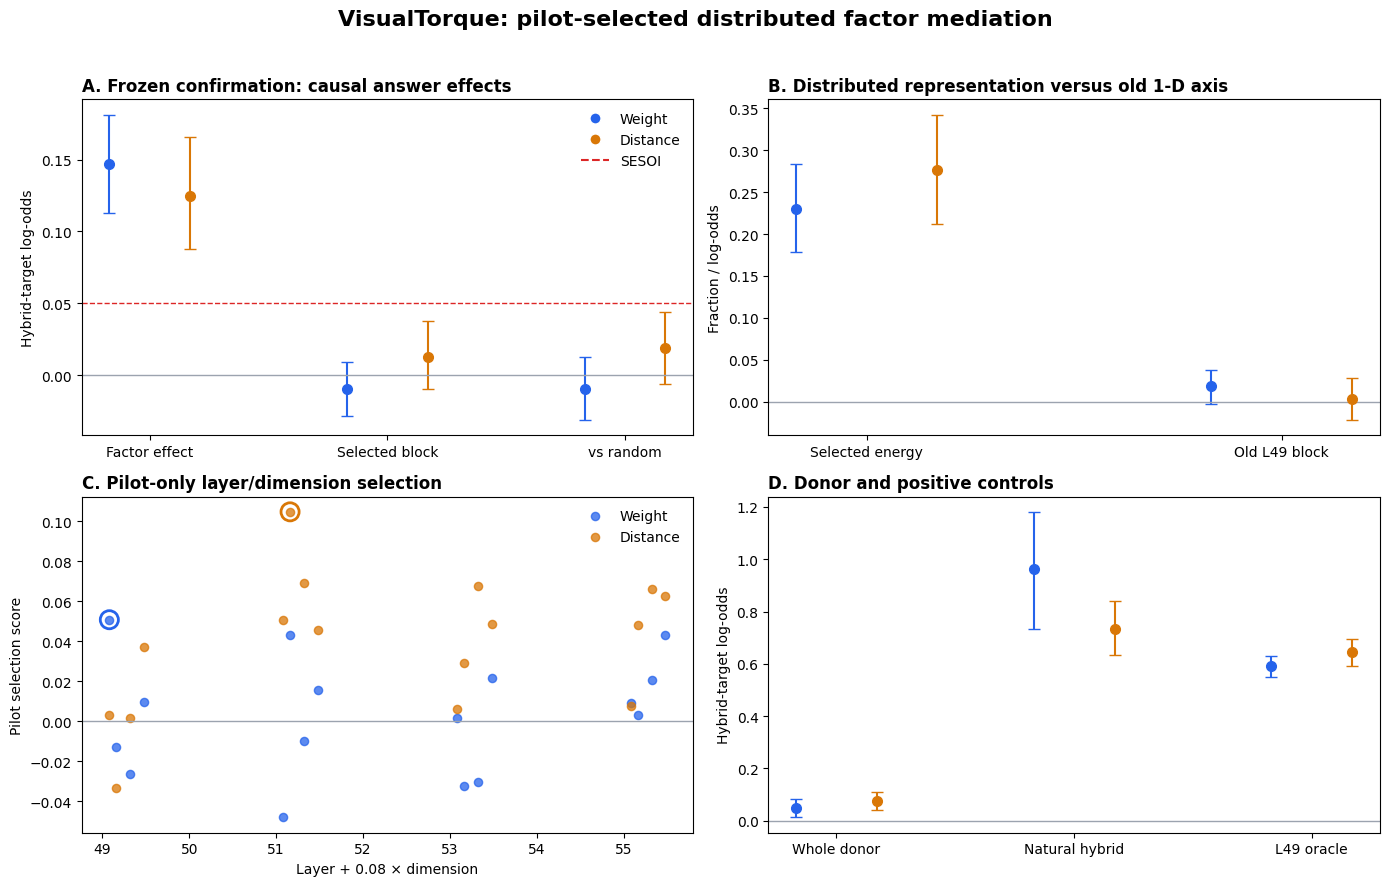

Saved: /content/drive/MyDrive/VisualTorque/results/qwen27b_distributed_factor_mediator_subspace_v1/analysis/figures/distributed_factor_mediator_confirmation.png


In [17]:
%%cell_progress 16/17 Save the paper-facing mediator figure
cell_stage('Rendering confirmation effects, energy, pilot selection, and controls')
import matplotlib.pyplot as plt

factor_labels = {'weight': 'Weight', 'distance': 'Distance'}
factor_colors = {'weight': '#2563EB', 'distance': '#D97706'}

def metric_panel(axis, metrics, title, ylabel, zero=True):
    labels = []
    positions = []
    offset = 0
    width = 0.34
    for metric_index, (metric, label) in enumerate(metrics):
        for factor_index, factor in enumerate(FACTORS):
            row = test_frame[
                (test_frame['factor'] == factor)
                & (test_frame['metric'] == metric)
            ].iloc[0]
            x_value = metric_index + (factor_index - 0.5) * width
            estimate = float(row['estimate'])
            axis.errorbar(
                [x_value], [estimate],
                yerr=[[estimate - float(row['ci_low'])],
                      [float(row['ci_high']) - estimate]],
                fmt='o', capsize=4, color=factor_colors[factor],
                markersize=7,
            )
        positions.append(metric_index)
        labels.append(label)
    if zero:
        axis.axhline(0, color='#9CA3AF', linewidth=1)
    axis.set_xticks(positions, labels)
    axis.set_ylabel(ylabel)
    axis.set_title(title, loc='left', fontweight='bold')

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
metric_panel(
    axes[0, 0],
    [('additive_total', 'Factor effect'),
     ('selected_attenuation', 'Selected block'),
     ('specificity', 'vs random')],
    'A. Frozen confirmation: causal answer effects',
    'Hybrid-target log-odds',
)
axes[0, 0].axhline(
    MEDIATION_SESOI_LOGODDS, color='#DC2626', linestyle='--',
    linewidth=1, label='mediation SESOI',
)
axes[0, 0].legend(
    handles=[plt.Line2D([0], [0], marker='o', color='w',
             markerfacecolor=factor_colors[factor], markersize=8,
             label=factor_labels[factor]) for factor in FACTORS]
    + [plt.Line2D([0], [0], color='#DC2626', linestyle='--',
       label='SESOI')], frameon=False,
)

metric_panel(
    axes[0, 1],
    [('explained_energy', 'Selected energy'),
     ('canonical_l49_attenuation', 'Old L49 block')],
    'B. Distributed representation versus old 1-D axis',
    'Fraction / log-odds',
)

for factor in FACTORS:
    subset = candidate_summary[candidate_summary['factor'] == factor]
    axes[1, 0].scatter(
        subset['layer_index'] + 0.08 * subset['dimension'],
        subset['selection_score'], s=35,
        color=factor_colors[factor], alpha=0.75,
        label=factor_labels[factor],
    )
    chosen = selection[factor]
    chosen_row = subset[
        (subset['layer_index'] == chosen['layer_index'])
        & (subset['dimension'] == chosen['dimension'])
    ].iloc[0]
    axes[1, 0].scatter(
        [chosen['layer_index'] + 0.08 * chosen['dimension']],
        [chosen_row['selection_score']], s=170, facecolors='none',
        edgecolors=factor_colors[factor], linewidths=2,
    )
axes[1, 0].axhline(0, color='#9CA3AF', linewidth=1)
axes[1, 0].set_xlabel('Layer + 0.08 × dimension')
axes[1, 0].set_ylabel('Pilot selection score')
axes[1, 0].set_title('C. Pilot-only layer/dimension selection',
                     loc='left', fontweight='bold')
axes[1, 0].legend(frameon=False)

metric_panel(
    axes[1, 1],
    [('whole_donor', 'Whole donor'),
     ('natural_hybrid', 'Natural hybrid'),
     ('l49_oracle', 'L49 oracle')],
    'D. Donor and positive controls',
    'Hybrid-target log-odds',
)
fig.suptitle(
    'VisualTorque: pilot-selected distributed factor mediation',
    fontsize=16, fontweight='bold',
)
fig.tight_layout(rect=[0, 0, 1, 0.96])
figure_path = FIGURE_DIR / 'distributed_factor_mediator_confirmation.png'
fig.savefig(figure_path, dpi=220, bbox_inches='tight')
plt.show()
print('Saved:', figure_path)


In [18]:
%%cell_progress 17/17 Write the decision, report, and completion manifest
cell_stage('Saving paper-facing tables and explicit claim boundaries')

decision_document = json.loads(
    (ANALYSIS_DIR / 'distributed_mediator_decision.json').read_text(
        encoding='utf-8'
    )
)
audit_document = json.loads(
    (ANALYSIS_DIR / 'robustness_audit.json').read_text(encoding='utf-8')
)

paper_rows = []
for factor in FACTORS:
    row = {
        'factor': factor,
        'selected_layer': selection[factor]['layer_index'],
        'selected_dimension': selection[factor]['dimension'],
        'confirmed': factor_decisions[factor]['confirmed'],
    }
    for metric in (
        'additive_total', 'selected_attenuation', 'specificity',
        'explained_energy', 'canonical_l49_attenuation', 'fanout_min',
    ):
        result = test_for(factor, metric)
        row[f'{metric}_estimate'] = result['estimate']
        row[f'{metric}_ci_low'] = result['ci_low']
        row[f'{metric}_ci_high'] = result['ci_high']
    paper_rows.append(row)
paper_table = pd.DataFrame(paper_rows)
paper_table.to_csv(ANALYSIS_DIR / 'paper_table.csv', index=False)

def interval_text(factor, metric):
    row = test_for(factor, metric)
    return (
        f"{row['estimate']:.3f} "
        f"[{row['ci_low']:.3f}, {row['ci_high']:.3f}]"
    )

lines = [
    '# Distributed Factor-Mediator Subspace: Frozen Result', '',
    f"**Primary decision:** `{primary_decision}`", '',
    '## What was tested', '',
    (
        'The layer and dimensionality were selected separately for weight and '
        'distance using only four pilot families per factor. The resulting '
        'basis was frozen and tested on 20 different confirmation families '
        'per factor, each evaluated in two target backgrounds.'
    ), '',
]
for factor in FACTORS:
    chosen = selection[factor]
    gates = factor_decisions[factor]['gates']
    lines.extend([
        f"## {factor.title()}", '',
        (
            f"Selected L{chosen['layer_index']} with "
            f"{chosen['dimension']} dimensions."
        ), '',
        f"- Factor answer effect: {interval_text(factor, 'additive_total')}",
        f"- Attenuation after selected-subspace removal: "
        f"{interval_text(factor, 'selected_attenuation')}",
        f"- Specificity over equal-norm random removal: "
        f"{interval_text(factor, 'specificity')}",
        f"- Factor-delta energy in the subspace: "
        f"{interval_text(factor, 'explained_energy')}",
        f"- Old one-dimensional L49 attenuation: "
        f"{interval_text(factor, 'canonical_l49_attenuation')}",
        f"- Frozen gates: `{json.dumps(gates, sort_keys=True)}`", '',
    ])
lines.extend([
    '## Claim boundary', '',
    (
        'A positive result supports a low-dimensional mediator for this '
        'specific decision-neutral factor transport at the frozen site. A '
        'negative result rules out this selected layer/dimension account, not '
        'all distributed computation or all forms of physical composition.'
    ), '',
    (
        'The confirmation families are held out from the present subspace fit '
        'but were already evaluated in the preceding experiment. Therefore '
        'this notebook is a mechanism follow-up, not a globally independent '
        'dataset replication.'
    ), '',
    '## Robustness', '',
    f"- Maximum self-replay centered error: "
    f"{audit_document['max_centered_self_replay_error']:.6f}",
    f"- Maximum equal-norm relative error: "
    f"{audit_document['max_equal_norm_relative_error']:.6g}",
    f"- Non-finite values: {audit_document['nonfinite_count']}",
])
report_path = ANALYSIS_DIR / 'DISTRIBUTED_MEDIATOR_REPORT.md'
report_path.write_text('\n'.join(lines) + '\n', encoding='utf-8')

completion = {
    'schema_version': 'qwen27b-distributed-factor-mediator-complete-1.0',
    'completed_at_utc': datetime.now(timezone.utc).isoformat(),
    'model_id': MODEL_ID,
    'revision': MODEL_REVISION,
    'primary_decision': primary_decision,
    'factor_decisions': factor_decisions,
    'pilot_families': len(pilot_manifest),
    'confirmation_families': len(confirmation_manifest),
    'confirmation_records': len(record_frame),
    'selection_path': str(SELECTION_PATH),
    'basis_path': str(BASIS_PATH),
    'report_path': str(report_path),
    'figure_path': str(figure_path),
    'protocol_sha256': sha256_file(PROTOCOL_LOCK_PATH),
}
write_json_atomic(SHARED_ROOT / 'RUN_COMPLETE.json', completion)
display(paper_table.round(4))
print('Primary decision:', primary_decision)
print('Report:', report_path)
print('Run complete:', SHARED_ROOT / 'RUN_COMPLETE.json')


Write the decision, report, and completion manifest:  94%|#########4| 16/17 [00:00<?, ?cell/s]

,factor,selected_layer,selected_dimension,confirmed,additive_total_estimate,additive_total_ci_low,additive_total_ci_high,selected_attenuation_estimate,selected_attenuation_ci_low,selected_attenuation_ci_high,...,specificity_ci_high,explained_energy_estimate,explained_energy_ci_low,explained_energy_ci_high,canonical_l49_attenuation_estimate,canonical_l49_attenuation_ci_low,canonical_l49_attenuation_ci_high,fanout_min_estimate,fanout_min_ci_low,fanout_min_ci_high
0,weight,49,1,False,0.1469,0.1125,0.1812,-0.0094,-0.0281,0.0094,...,0.0125,0.2294,0.1791,0.2833,0.0187,-0.0031,0.0375,0.1125,0.0750,0.15
1,distance,51,2,False,0.1250,0.0875,0.1656,0.0125,-0.0094,0.0375,...,0.0438,0.2758,0.2123,0.3423,0.0031,-0.0219,0.0281,0.0687,0.0375,0.10


Primary decision: factor_effect_without_confirmed_distributed_mediator
Report: /content/drive/MyDrive/VisualTorque/results/qwen27b_distributed_factor_mediator_subspace_v1/analysis/DISTRIBUTED_MEDIATOR_REPORT.md
Run complete: /content/drive/MyDrive/VisualTorque/results/qwen27b_distributed_factor_mediator_subspace_v1/RUN_COMPLETE.json
